In [3]:
import os
print(os.listdir("/kaggle/input"))
import torch
print(torch.cuda.is_available(), torch.cuda.device_count())

['notebooks', 'datasets']
True 2


In [4]:
import os
for d, _, f in os.walk("/kaggle/input"):
    if "HAM10000_metadata.csv" in f:
        print("ROOT =", d)

ROOT = /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000


In [5]:
import os, pandas as pd
from sklearn.model_selection import train_test_split

root = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
df = pd.read_csv(f"{root}/HAM10000_metadata.csv")

# saari images ka path dhundo (folder naam kuch bhi ho)
paths = {}
for d, _, files in os.walk(root):
    for f in files:
        if f.endswith(".jpg"):
            paths[f[:-4]] = os.path.join(d, f)
df["path"] = df["image_id"].map(paths)
print("images mili:", df.path.notna().sum(), "/", len(df))

classes = sorted(df.dx.unique())
df["label"] = df.dx.map({c: i for i, c in enumerate(classes)})

# lesion_id ke basis par split
les = df.groupby("lesion_id").first().reset_index()
tr, tmp = train_test_split(les, test_size=0.3, stratify=les.dx, random_state=42)
va, te = train_test_split(tmp, test_size=0.5, stratify=tmp.dx, random_state=42)

df["split"] = "train"
df.loc[df.lesion_id.isin(va.lesion_id), "split"] = "val"
df.loc[df.lesion_id.isin(te.lesion_id), "split"] = "test"
df[["image_id", "lesion_id", "dx", "label", "split"]].to_csv("split.csv", index=False)

print(df.split.value_counts())
print(classes)

images mili: 10015 / 10015
split
train    6981
val      1532
test     1502
Name: count, dtype: int64
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
path             0
label            0
split            0
dtype: int64
dx     akiec  bcc  bkl  df  mel    nv  vasc
split                                      
test      52   71  167  20  167  1004    21
train    222  361  772  71  773  4683    99
val       53   82  160  24  173  1018    22


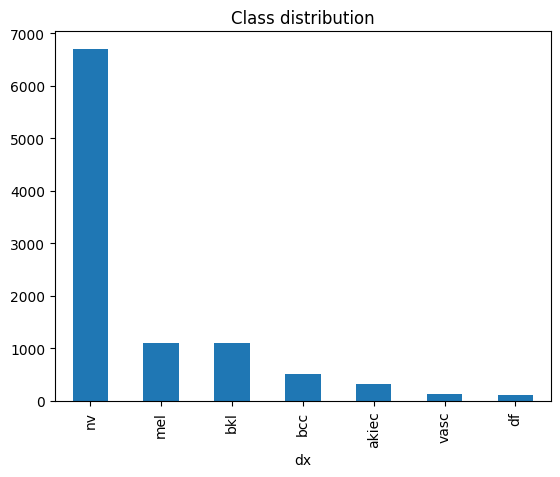

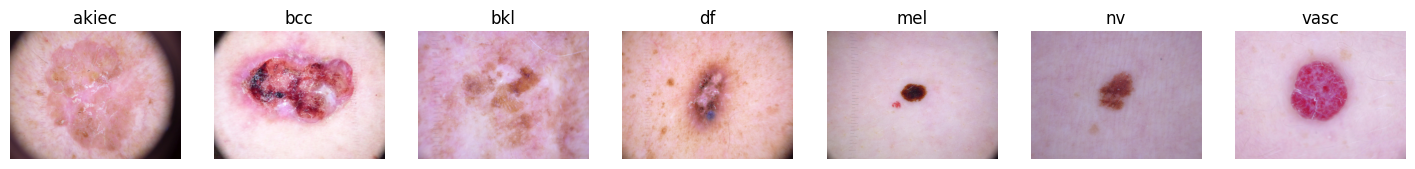

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

print(df.dx.value_counts())
print(df.isna().sum())
print(df.groupby("split").dx.value_counts().unstack())

# class distribution plot
df.dx.value_counts().plot(kind="bar", title="Class distribution")
plt.show()

# har class ki ek sample image
fig, ax = plt.subplots(1, 7, figsize=(18, 3))
for a, c in zip(ax, classes):
    a.imshow(Image.open(df[df.dx == c].iloc[0].path))
    a.set_title(c); a.axis("off")
plt.show()

In [7]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = T.Compose([T.Resize((224, 224)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                      T.RandomRotation(20), T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), norm])
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), norm])

class HAMDataset(Dataset):
    def __init__(self, d, tf):
        self.d, self.tf = d.reset_index(drop=True), tf
    def __len__(self):
        return len(self.d)
    def __getitem__(self, i):
        r = self.d.iloc[i]
        return self.tf(Image.open(r.path).convert("RGB")), r.label, r.image_id

sets = {s: df[df.split == s] for s in ["train", "val", "test"]}
tl  = DataLoader(HAMDataset(sets["train"], train_tf), batch_size=32, shuffle=True, num_workers=2)
vl  = DataLoader(HAMDataset(sets["val"], eval_tf), batch_size=32, num_workers=2)
tel = DataLoader(HAMDataset(sets["test"], eval_tf), batch_size=32, num_workers=2)

x, y, ids = next(iter(tl))
print(x.shape, y[:8], ids[:3])

torch.Size([32, 3, 224, 224]) tensor([5, 6, 5, 5, 5, 5, 5, 5]) ('ISIC_0028598', 'ISIC_0025578', 'ISIC_0025354')


In [8]:
print(torch.cuda.is_available(), torch.cuda.device_count())

True 2


In [9]:
import torch.nn as nn, numpy as np
from torchvision import models
from sklearn.metrics import f1_score

dev = "cuda"
m = models.resnet18(weights="IMAGENET1K_V1")
m.fc = nn.Linear(512, 7)
m = m.to(dev)

# class weights (imbalance ke liye)
cnt = sets["train"].label.value_counts().sort_index().values
w = torch.tensor(cnt.sum() / (7 * cnt), dtype=torch.float).to(dev)
crit = nn.CrossEntropyLoss(weight=w)
opt = torch.optim.Adam(m.parameters(), lr=1e-4)

def evaluate(loader):
    m.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y, _ in loader:
            P += m(x.to(dev)).argmax(1).cpu().tolist()
            Y += y.tolist()
    return np.mean(np.array(P) == np.array(Y)), f1_score(Y, P, average="macro"), Y, P

EPOCHS = 1   # pehle 1 rakho, test ke liye
best = 0
for ep in range(EPOCHS):
    m.train()
    for x, y, _ in tl:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad()
        crit(m(x), y).backward()
        opt.step()
    acc, f1, _, _ = evaluate(vl)
    print(f"epoch {ep}: val acc {acc:.3f}, macro-F1 {f1:.3f}")
    if f1 > best:
        best = f1
        torch.save(m.state_dict(), "resnet18_best.pth")

epoch 0: val acc 0.514, macro-F1 0.411


In [10]:
import torch.nn as nn, numpy as np
from torchvision import models
from sklearn.metrics import f1_score

dev = "cuda"
m = models.resnet18(weights="IMAGENET1K_V1")
m.fc = nn.Linear(512, 7)
m = m.to(dev)

# class weights (imbalance ke liye)
cnt = sets["train"].label.value_counts().sort_index().values
w = torch.tensor(cnt.sum() / (7 * cnt), dtype=torch.float).to(dev)
crit = nn.CrossEntropyLoss(weight=w)
opt = torch.optim.Adam(m.parameters(), lr=1e-4)

def evaluate(loader):
    m.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y, _ in loader:
            P += m(x.to(dev)).argmax(1).cpu().tolist()
            Y += y.tolist()
    return np.mean(np.array(P) == np.array(Y)), f1_score(Y, P, average="macro"), Y, P

EPOCHS = 15   # pehle 1 rakho, test ke liye
best = 0
for ep in range(EPOCHS):
    m.train()
    for x, y, _ in tl:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad()
        crit(m(x), y).backward()
        opt.step()
    acc, f1, _, _ = evaluate(vl)
    print(f"epoch {ep}: val acc {acc:.3f}, macro-F1 {f1:.3f}")
    if f1 > best:
        best = f1
        torch.save(m.state_dict(), "resnet18_best.pth")

epoch 0: val acc 0.597, macro-F1 0.491
epoch 1: val acc 0.601, macro-F1 0.483
epoch 2: val acc 0.659, macro-F1 0.533
epoch 3: val acc 0.701, macro-F1 0.578
epoch 4: val acc 0.740, macro-F1 0.554
epoch 5: val acc 0.733, macro-F1 0.648
epoch 6: val acc 0.790, macro-F1 0.671
epoch 7: val acc 0.766, macro-F1 0.627
epoch 8: val acc 0.767, macro-F1 0.604
epoch 9: val acc 0.738, macro-F1 0.619
epoch 10: val acc 0.777, macro-F1 0.651
epoch 11: val acc 0.801, macro-F1 0.680
epoch 12: val acc 0.762, macro-F1 0.584
epoch 13: val acc 0.757, macro-F1 0.601
epoch 14: val acc 0.775, macro-F1 0.652


test acc 0.779, macro-F1 0.658
              precision    recall  f1-score   support

       akiec       0.56      0.63      0.59        52
         bcc       0.58      0.72      0.64        71
         bkl       0.55      0.63      0.59       167
          df       0.56      0.70      0.62        20
         mel       0.49      0.56      0.52       167
          nv       0.93      0.85      0.89      1004
        vasc       0.79      0.71      0.75        21

    accuracy                           0.78      1502
   macro avg       0.64      0.69      0.66      1502
weighted avg       0.80      0.78      0.79      1502



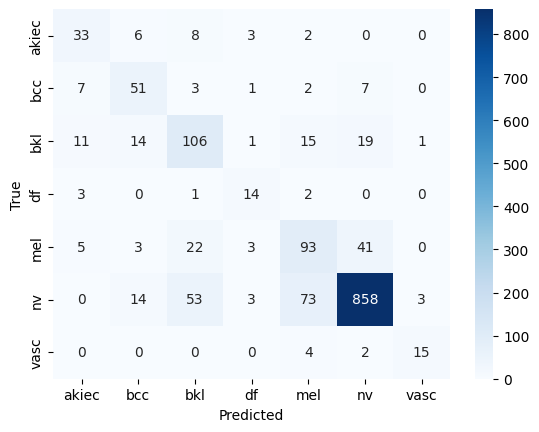

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns, matplotlib.pyplot as plt

m.load_state_dict(torch.load("resnet18_best.pth"))
acc, f1, Y, P = evaluate(tel)
print(f"test acc {acc:.3f}, macro-F1 {f1:.3f}")
print(classification_report(Y, P, target_names=classes))

cm = confusion_matrix(Y, P)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
import pandas as pd, json
from sklearn.metrics import classification_report

m.load_state_dict(torch.load("resnet18_best.pth"))
m.eval(); rows = []
with torch.no_grad():
    for x, y, ids in tel:
        p = torch.softmax(m(x.to(dev)), 1).cpu().numpy()
        for i, pi, yi in zip(ids, p, y.tolist()):
            rows.append([i, yi, int(pi.argmax())] + list(pi))
cols = ["image_id", "true", "pred"] + [f"p_{c}" for c in classes]
pd.DataFrame(rows, columns=cols).to_csv("image_only_test_preds.csv", index=False)

json.dump(classification_report(Y, P, target_names=classes, output_dict=True),
          open("image_only_metrics.json", "w"), indent=2)

In [13]:
print(os.listdir("/kaggle/working"))

['image_only_test_preds.csv', 'image_only_metrics.json', '.virtual_documents', 'split.csv', 'confusion_matrix.png', 'resnet18_best.pth']


In [16]:
HAM = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"
SPLIT = "/kaggle/working"
print(HAM)
print(SPLIT)

/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
/kaggle/working


In [17]:
import pandas as pd, numpy as np, json, joblib
import matplotlib.pyplot as plt, seaborn as sns

meta = pd.read_csv(f"{HAM}/HAM10000_metadata.csv")
sp = pd.read_csv(f"{SPLIT}/split.csv")
df_c = meta.merge(sp[["image_id", "label", "split"]], on="image_id")
classes = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

print(len(df_c), df_c.split.value_counts().to_dict())
print(df_c.isna().sum())
print(df_c.sex.value_counts())
print(df_c.localization.value_counts())

10015 {'train': 6981, 'val': 1532, 'test': 1502}
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
label            0
split            0
dtype: int64
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7
Name: count, dtype: int64


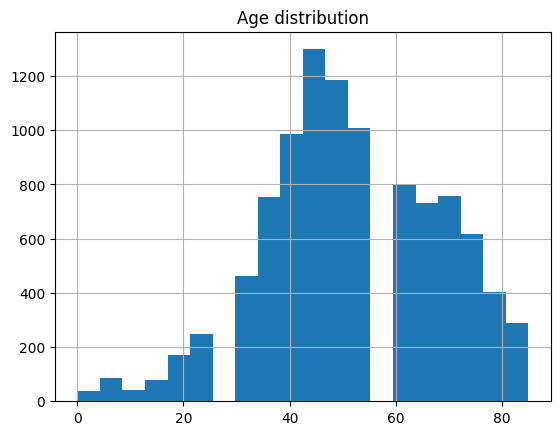

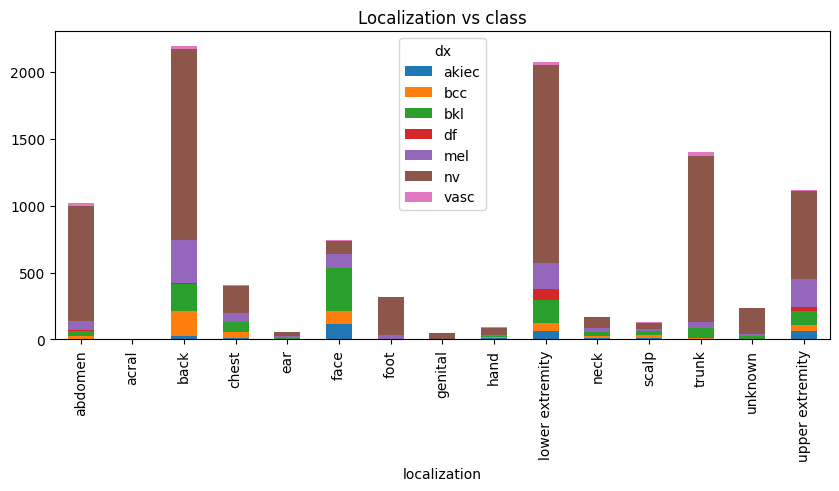

dx
akiec    66.5
bcc      66.8
bkl      64.3
df       53.0
mel      60.7
nv       46.5
vasc     51.4
Name: age, dtype: float64
sex
unknown    47
male        6
female      4
Name: count, dtype: int64


In [18]:
df_c.age.hist(bins=20)
plt.title("Age distribution"); plt.show()

pd.crosstab(df_c.localization, df_c.dx).plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Localization vs class"); plt.show()

print(df_c.groupby("dx").age.mean().round(1))
print(df_c[df_c.age.isna()].sex.value_counts())

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num, cat = ["age"], ["sex", "localization"]
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])

tr, va, te = [df_c[df_c.split == s] for s in ["train", "val", "test"]]
Xtr = pre.fit_transform(tr[num + cat]).astype("float32")   # fit sirf train par
Xva = pre.transform(va[num + cat]).astype("float32")
Xte = pre.transform(te[num + cat]).astype("float32")
ytr, yva, yte = tr.label.values, va.label.values, te.label.values

joblib.dump(pre, "clinical_preprocessor.joblib")
print(Xtr.shape, Xva.shape, Xte.shape)
print("NaN:", np.isnan(Xtr).sum())

(6981, 19) (1532, 19) (1502, 19)
NaN: 0


In [20]:
import torch, torch.nn as nn
from sklearn.metrics import f1_score, classification_report

cdev = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

class ClinicalMLP(nn.Module):
    def __init__(self, d_in, emb=32, n_cls=7):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Dropout(0.2),
                                     nn.Linear(64, emb), nn.ReLU())
        self.head = nn.Linear(emb, n_cls)
    def forward(self, x): return self.head(self.encoder(x))

mlp = ClinicalMLP(Xtr.shape[1]).to(cdev)
c_cnt = np.bincount(ytr, minlength=7)
c_w = torch.tensor(c_cnt.sum() / (7 * c_cnt), dtype=torch.float).to(cdev)
c_crit = nn.CrossEntropyLoss(weight=c_w)
c_opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)

def c_predict(X):
    mlp.eval()
    with torch.no_grad():
        return torch.softmax(mlp(torch.tensor(X).to(cdev)), 1).cpu().numpy()

Xt, yt = torch.tensor(Xtr), torch.tensor(ytr)
c_best = 0
for ep in range(60):
    mlp.train()
    perm = torch.randperm(len(Xt))
    for i in range(0, len(Xt), 128):
        idx = perm[i:i + 128]
        c_opt.zero_grad()
        c_crit(mlp(Xt[idx].to(cdev)), yt[idx].to(cdev)).backward()
        c_opt.step()
    f1 = f1_score(yva, c_predict(Xva).argmax(1), average="macro")
    if f1 > c_best:
        c_best = f1
        torch.save(mlp.state_dict(), "clinical_mlp_best.pth")
    if ep % 10 == 0: print(ep, round(f1, 3))
print("best val macro-F1:", round(c_best, 3))

0 0.214
10 0.181
20 0.197
30 0.195
40 0.206
50 0.211
best val macro-F1: 0.23


              precision    recall  f1-score   support

       akiec       0.17      0.50      0.26        52
         bcc       0.16      0.37      0.23        71
         bkl       0.37      0.11      0.17       167
          df       0.04      0.65      0.07        20
         mel       0.30      0.15      0.20       167
          nv       0.87      0.43      0.58      1004
        vasc       0.02      0.14      0.03        21

    accuracy                           0.36      1502
   macro avg       0.27      0.34      0.22      1502
weighted avg       0.67      0.36      0.45      1502



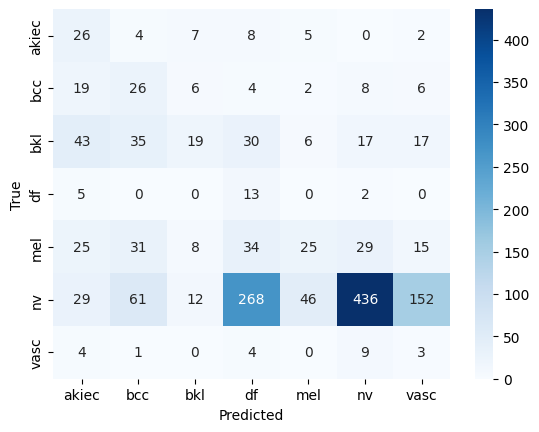

In [21]:
from sklearn.metrics import confusion_matrix

mlp.load_state_dict(torch.load("clinical_mlp_best.pth"))
Pc = c_predict(Xte)
predc = Pc.argmax(1)
print(classification_report(yte, predc, target_names=classes))

sns.heatmap(confusion_matrix(yte, predc), annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.savefig("clinical_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

out = pd.DataFrame({"image_id": te.image_id.values, "true": yte, "pred": predc})
for i, c in enumerate(classes): out[f"p_{c}"] = Pc[:, i]
out.to_csv("clinical_only_test_preds.csv", index=False)
json.dump(classification_report(yte, predc, target_names=classes, output_dict=True),
          open("clinical_only_metrics.json", "w"), indent=2)

sex             0.000368
age             0.063878
localization    0.090319
dtype: float64


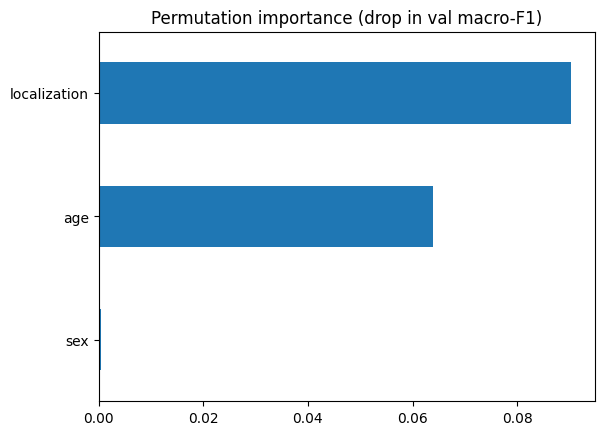

In [22]:
rng = np.random.default_rng(42)
base = f1_score(yva, c_predict(Xva).argmax(1), average="macro")
res = {}
for f in num + cat:
    drops = []
    for _ in range(10):
        d = va[num + cat].copy()
        d[f] = rng.permutation(d[f].values)
        Xp = pre.transform(d).astype("float32")
        drops.append(base - f1_score(yva, c_predict(Xp).argmax(1), average="macro"))
    res[f] = np.mean(drops)

imp = pd.Series(res).sort_values()
print(imp)
imp.plot(kind="barh", title="Permutation importance (drop in val macro-F1)")
plt.savefig("clinical_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
print(os.listdir("/kaggle/working"))

['image_only_test_preds.csv', 'clinical_only_test_preds.csv', 'clinical_confusion_matrix.png', 'image_only_metrics.json', 'clinical_mlp_best.pth', '.virtual_documents', 'split.csv', 'confusion_matrix.png', 'resnet18_best.pth', 'clinical_only_metrics.json', 'clinical_feature_importance.png', 'clinical_preprocessor.joblib']


In [24]:
for v in ["m", "mlp", "pre", "sets", "eval_tf", "HAMDataset", "Xtr", "Xva", "Xte", "tr", "va", "te", "classes", "dev"]:
    print(v, v in globals())

m True
mlp True
pre True
sets True
eval_tf True
HAMDataset True
Xtr True
Xva True
Xte True
tr True
va True
te True
classes True
dev True


In [25]:
import torch, torch.nn as nn, numpy as np, pandas as pd, json
from torch.utils.data import DataLoader

m.load_state_dict(torch.load("resnet18_best.pth"))
m.eval()
backbone = nn.Sequential(*list(m.children())[:-1])   # fc hata diya, output 512-d

def img_feats(d):
    loader = DataLoader(HAMDataset(d, eval_tf), batch_size=64, num_workers=2)
    F, ids = [], []
    with torch.no_grad():
        for x, y, i in loader:
            F.append(backbone(x.to(dev)).flatten(1).cpu())
            ids += list(i)
    return torch.cat(F).numpy(), ids

cl = {"train": (tr, Xtr), "val": (va, Xva), "test": (te, Xte)}
data = {}
for s in ["train", "val", "test"]:
    F, ids = img_feats(sets[s])
    d, X = cl[s]
    Xa = pd.DataFrame(X, index=d.image_id.values).loc[ids].values.astype("float32")   # image_id se align
    y = sets[s].label.values
    assert (d.set_index("image_id").loc[ids].label.values == y).all()
    data[s] = (F.astype("float32"), Xa, y, ids)
    print(s, F.shape, Xa.shape)

train (6981, 512) (6981, 19)
val (1532, 512) (1532, 19)
test (1502, 512) (1502, 19)


In [26]:
import copy
from sklearn.metrics import f1_score, classification_report, confusion_matrix

class FusionNet(nn.Module):
    def __init__(self, clin_mlp, d_img=512, n_cls=7):
        super().__init__()
        self.clin = copy.deepcopy(clin_mlp.encoder)     # 19 -> 32
        self.img_drop = nn.Dropout(0.3)
        self.head = nn.Sequential(nn.Linear(d_img + 32, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, n_cls))
    def forward(self, f_img, x_clin):
        z = torch.cat([self.img_drop(f_img), self.clin(x_clin)], 1)   # 512 + 32 = 544
        return self.head(z)

torch.manual_seed(42)
fus = FusionNet(mlp).to(dev)
Ftr, Ctr, ytr_f, _ = data["train"]
Fva, Cva, yva_f, _ = data["val"]
Fte, Cte, yte_f, ids_te = data["test"]

cnt = np.bincount(ytr_f, minlength=7)
w_f = torch.tensor(cnt.sum() / (7 * cnt), dtype=torch.float).to(dev)
f_crit = nn.CrossEntropyLoss(weight=w_f)
f_opt = torch.optim.Adam(fus.parameters(), lr=1e-3, weight_decay=1e-4)

def f_predict(F, C):
    fus.eval()
    with torch.no_grad():
        return torch.softmax(fus(torch.tensor(F).to(dev), torch.tensor(C).to(dev)), 1).cpu().numpy()

Ft, Ct, yt_t = torch.tensor(Ftr), torch.tensor(Ctr), torch.tensor(ytr_f)
f_best = 0
for ep in range(40):
    fus.train()
    perm = torch.randperm(len(Ft))
    for i in range(0, len(Ft), 128):
        idx = perm[i:i + 128]
        f_opt.zero_grad()
        f_crit(fus(Ft[idx].to(dev), Ct[idx].to(dev)), yt_t[idx].to(dev)).backward()
        f_opt.step()
    f1 = f1_score(yva_f, f_predict(Fva, Cva).argmax(1), average="macro")
    if f1 > f_best:
        f_best = f1
        torch.save(fus.state_dict(), "fusion_best.pth")
    if ep % 5 == 0: print(ep, round(f1, 3))
print("best val macro-F1:", round(f_best, 3))

0 0.681
5 0.702
10 0.654
15 0.698
20 0.7
25 0.709
30 0.702
35 0.692
best val macro-F1: 0.711


              precision    recall  f1-score   support

       akiec       0.55      0.65      0.60        52
         bcc       0.69      0.77      0.73        71
         bkl       0.64      0.65      0.65       167
          df       0.71      0.75      0.73        20
         mel       0.52      0.65      0.58       167
          nv       0.93      0.88      0.91      1004
        vasc       0.94      0.76      0.84        21

    accuracy                           0.81      1502
   macro avg       0.71      0.73      0.72      1502
weighted avg       0.83      0.81      0.82      1502



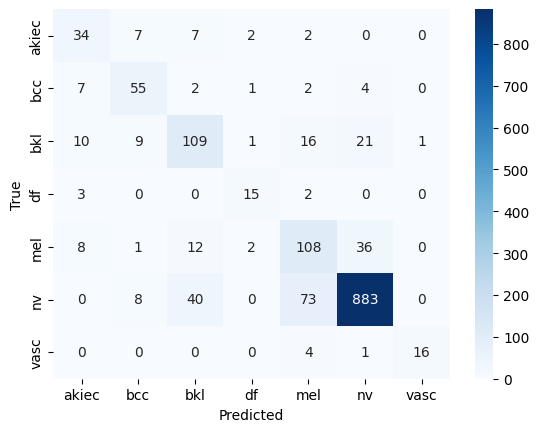

In [27]:
fus.load_state_dict(torch.load("fusion_best.pth"))
Pf = f_predict(Fte, Cte)
predf = Pf.argmax(1)
print(classification_report(yte_f, predf, target_names=classes))

import seaborn as sns, matplotlib.pyplot as plt
sns.heatmap(confusion_matrix(yte_f, predf), annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.savefig("fusion_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

out = pd.DataFrame({"image_id": ids_te, "true": yte_f, "pred": predf})
for i, c in enumerate(classes): out[f"p_{c}"] = Pf[:, i]
out.to_csv("fusion_test_preds.csv", index=False)
json.dump(classification_report(yte_f, predf, target_names=classes, output_dict=True),
          open("fusion_metrics.json", "w"), indent=2)

           Model  Accuracy  Macro-F1  Weighted-F1  Melanoma recall
0     Image only     0.779     0.658        0.787            0.557
1  Clinical only     0.365     0.219        0.450            0.150
2         Fusion     0.812     0.718        0.818            0.647


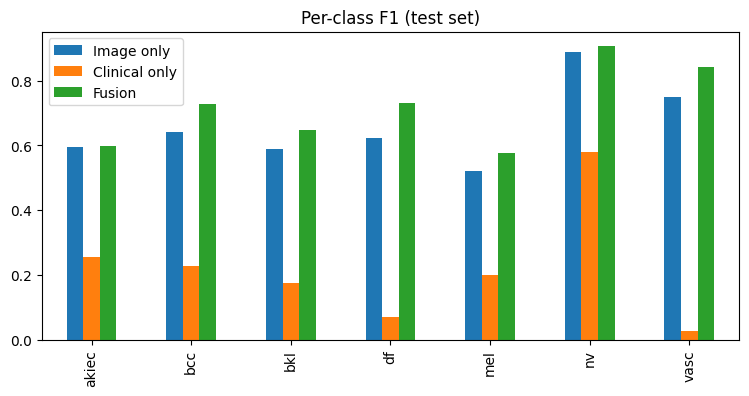

In [28]:
files = [("Image only", "image_only_metrics.json"),
         ("Clinical only", "clinical_only_metrics.json"),
         ("Fusion", "fusion_metrics.json")]

rows = []
for name, f in files:
    r = json.load(open(f))
    rows.append({"Model": name, "Accuracy": r["accuracy"],
                 "Macro-F1": r["macro avg"]["f1-score"],
                 "Weighted-F1": r["weighted avg"]["f1-score"],
                 "Melanoma recall": r["mel"]["recall"]})
cmp = pd.DataFrame(rows).round(3)
print(cmp)
cmp.to_csv("comparison_table.csv", index=False)

pc = pd.DataFrame({n: [json.load(open(f))[c]["f1-score"] for c in classes] for n, f in files}, index=classes)
pc.plot(kind="bar", figsize=(9, 4), title="Per-class F1 (test set)")
plt.savefig("comparison_per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()

In [29]:
import os, sklearn, torch, torchvision
print(os.listdir("/kaggle/working"))
print(sklearn.__version__, torch.__version__, torchvision.__version__)

['image_only_test_preds.csv', 'clinical_only_test_preds.csv', 'clinical_confusion_matrix.png', 'comparison_table.csv', 'fusion_test_preds.csv', 'image_only_metrics.json', 'clinical_mlp_best.pth', '.virtual_documents', 'split.csv', 'confusion_matrix.png', 'fusion_best.pth', 'resnet18_best.pth', 'clinical_only_metrics.json', 'fusion_confusion_matrix.png', 'clinical_feature_importance.png', 'comparison_per_class_f1.png', 'clinical_preprocessor.joblib', 'fusion_metrics.json']
1.6.1 2.11.0+cu130 0.26.0+cu130


In [30]:
%%writefile fusion_utils.py
import numpy as np, pandas as pd, torch, torch.nn as nn, joblib
from torchvision import models as tvm, transforms as T
from PIL import Image
from matplotlib import cm

CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
FULL_NAMES = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesion",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevus",
    "vasc": "Vascular lesion",
}
SEXES = ["male", "female", "unknown"]
LOCALIZATIONS = ["abdomen", "acral", "back", "chest", "ear", "face", "foot", "genital",
                 "hand", "lower extremity", "neck", "scalp", "trunk", "unknown", "upper extremity"]

EVAL_TF = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                     T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])


class FusionNet(nn.Module):
    def __init__(self, d_clin=19, d_img=512, emb=32, n_cls=7):
        super().__init__()
        self.clin = nn.Sequential(nn.Linear(d_clin, 64), nn.ReLU(), nn.Dropout(0.2),
                                  nn.Linear(64, emb), nn.ReLU())
        self.img_drop = nn.Dropout(0.3)
        self.head = nn.Sequential(nn.Linear(d_img + emb, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, n_cls))

    def forward(self, f_img, x_clin):
        z = torch.cat([self.img_drop(f_img), self.clin(x_clin)], 1)
        return self.head(z)


class GradCAM:
    """Forward hook se activations aur unke gradients pakadta hai."""
    def __init__(self, layer):
        self.acts, self.grads = None, None
        layer.register_forward_hook(self._fwd)

    def _fwd(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))


def load_models(model_dir, device="cpu"):
    resnet = tvm.resnet18(weights=None)
    resnet.fc = nn.Linear(512, 7)
    resnet.load_state_dict(torch.load(f"{model_dir}/resnet18_best.pth", map_location=device))
    resnet.to(device).eval()
    backbone = nn.Sequential(*list(resnet.children())[:-1])   # 512-d features
    fusion = FusionNet()
    fusion.load_state_dict(torch.load(f"{model_dir}/fusion_best.pth", map_location=device))
    fusion.to(device).eval()
    pre = joblib.load(f"{model_dir}/clinical_preprocessor.joblib")
    cam = GradCAM(resnet.layer4)
    return resnet, backbone, fusion, pre, cam


def clinical_vector(pre, age, sex, loc):
    """age=None matlab unknown (training jaise median se impute hoga)."""
    row = pd.DataFrame([{"age": np.nan if age is None else float(age),
                         "sex": sex, "localization": loc}])
    return pre.transform(row[["age", "sex", "localization"]]).astype("float32")


def image_only_probs(resnet, img, device="cpu"):
    x = EVAL_TF(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        return torch.softmax(resnet(x), 1)[0].cpu().numpy()


def fusion_predict(img, clin_x, backbone, fusion, cam, device="cpu", target=None):
    """Return: probs (7,), predicted class index, heatmap (7x7, 0-1)."""
    x = EVAL_TF(img.convert("RGB")).unsqueeze(0).to(device)
    c = torch.tensor(clin_x, dtype=torch.float32).to(device)
    with torch.enable_grad():
        feats = backbone(x).flatten(1)
        logits = fusion(feats, c)
        probs = torch.softmax(logits, 1)[0]
        cls = int(probs.argmax()) if target is None else target
        backbone.zero_grad(); fusion.zero_grad()
        logits[0, cls].backward()
    w = cam.grads.mean(dim=(2, 3), keepdim=True)
    heat = torch.relu((w * cam.acts).sum(1))[0].detach().cpu().numpy()
    heat = heat / (heat.max() + 1e-8)
    return probs.detach().cpu().numpy(), cls, heat


def overlay(img, heat, alpha=0.4, size=224):
    base = np.array(img.convert("RGB").resize((size, size))) / 255.0
    h = np.array(Image.fromarray(np.uint8(255 * heat)).resize((size, size), Image.BILINEAR)) / 255.0
    colored = cm.jet(h)[..., :3]
    return np.uint8(255 * ((1 - alpha) * base + alpha * colored))

Writing fusion_utils.py


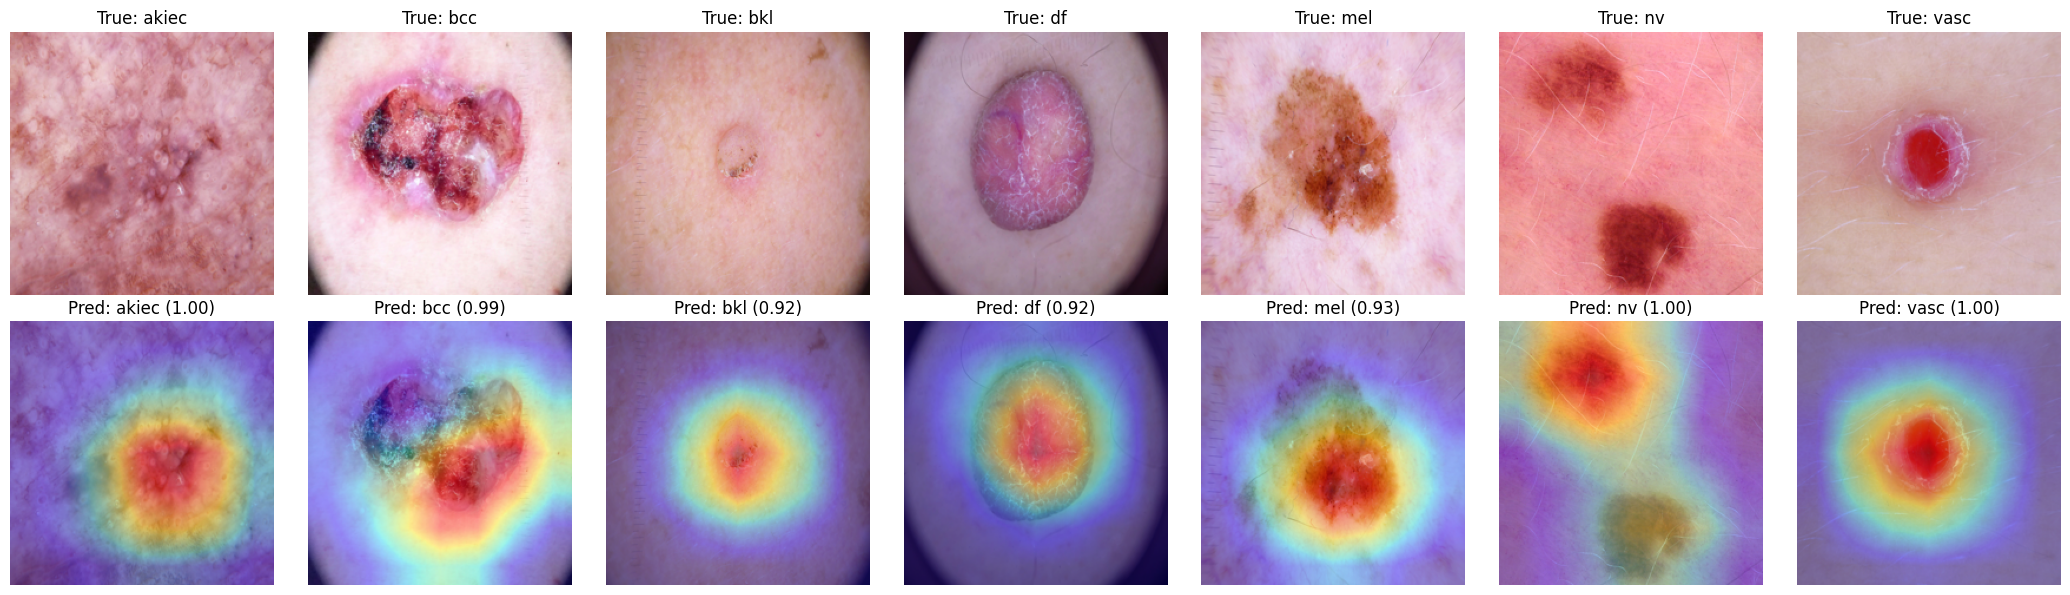

In [31]:
import importlib, fusion_utils as fu
importlib.reload(fu)
import pandas as pd, numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image

dv = "cuda" if torch.cuda.is_available() else "cpu"
resnet_g, backbone_g, fusion_g, pre_g, cam = fu.load_models("/kaggle/working", dv)

te_img = sets["test"].set_index("image_id")      # path, label
idx_of = {i: k for k, i in enumerate(ids_te)}    # Cte ke rows ke liye
pr = pd.read_csv("fusion_test_preds.csv")

fig, ax = plt.subplots(2, 7, figsize=(21, 6))
for j, c in enumerate(fu.CLASSES):
    iid = pr[(pr.true == j) & (pr.pred == j)].image_id.values[0]     # sahi predicted example
    pil = Image.open(te_img.loc[iid].path).convert("RGB")
    cvec = Cte[idx_of[iid]][None, :]
    probs, cls, heat = fu.fusion_predict(pil, cvec, backbone_g, fusion_g, cam, dv)
    ax[0, j].imshow(pil.resize((224, 224))); ax[0, j].set_title(f"True: {c}"); ax[0, j].axis("off")
    ax[1, j].imshow(fu.overlay(pil, heat)); ax[1, j].set_title(f"Pred: {fu.CLASSES[cls]} ({probs[cls]:.2f})"); ax[1, j].axis("off")
plt.tight_layout()
plt.savefig("gradcam_examples.png", dpi=150, bbox_inches="tight")
plt.show()

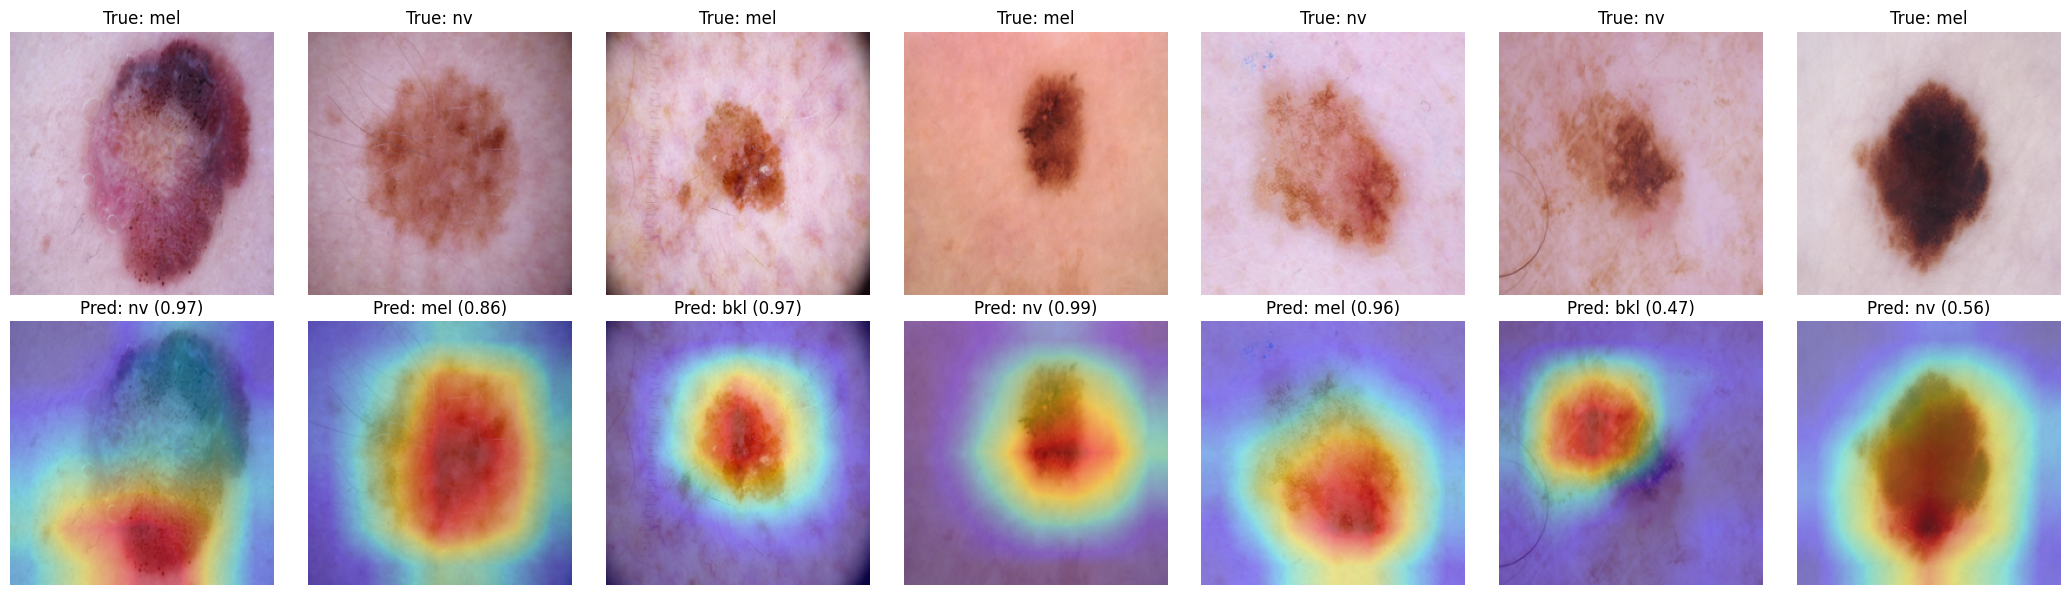

In [32]:
wrong = pr[pr.true != pr.pred].sample(7, random_state=1)
fig, ax = plt.subplots(2, 7, figsize=(21, 6))
for j, (_, r) in enumerate(wrong.iterrows()):
    pil = Image.open(te_img.loc[r.image_id].path).convert("RGB")
    cvec = Cte[idx_of[r.image_id]][None, :]
    probs, cls, heat = fu.fusion_predict(pil, cvec, backbone_g, fusion_g, cam, dv)
    ax[0, j].imshow(pil.resize((224, 224))); ax[0, j].set_title(f"True: {fu.CLASSES[int(r.true)]}"); ax[0, j].axis("off")
    ax[1, j].imshow(fu.overlay(pil, heat)); ax[1, j].set_title(f"Pred: {fu.CLASSES[cls]} ({probs[cls]:.2f})"); ax[1, j].axis("off")
plt.tight_layout()
plt.savefig("gradcam_errors.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
%%writefile app.py
import streamlit as st
import numpy as np, pandas as pd
from PIL import Image
import fusion_utils as fu

st.set_page_config(page_title="Multimodal Skin Lesion Diagnosis", layout="wide")


@st.cache_resource
def load():
    return fu.load_models("models", "cpu")


resnet, backbone, fusion, pre, cam = load()

st.title("Multimodal AI for Personalized Cancer Diagnosis")
st.caption("Dermoscopy image + patient metadata → lesion class prediction with Grad-CAM explanation. "
           "Research prototype, not for clinical use.")

with st.sidebar:
    st.header("Inputs")
    up = st.file_uploader("Dermoscopic image", type=["jpg", "jpeg", "png"])
    age_unknown = st.checkbox("Age unknown")
    age = None if age_unknown else st.number_input("Age", 0, 100, 50)
    sex = st.selectbox("Sex", fu.SEXES)
    loc = st.selectbox("Lesion localization", fu.LOCALIZATIONS, index=fu.LOCALIZATIONS.index("back"))
    go = st.button("Predict", type="primary")

if up is None:
    st.info("Sidebar se image upload karo aur metadata bharo.")
elif go:
    img = Image.open(up).convert("RGB")
    clin = fu.clinical_vector(pre, age, sex, loc)
    probs, cls, heat = fu.fusion_predict(img, clin, backbone, fusion, cam, "cpu")
    img_probs = fu.image_only_probs(resnet, img, "cpu")

    c1, c2 = st.columns(2)
    c1.subheader("Input image")
    c1.image(img.resize((224, 224)), use_container_width=True)
    c2.subheader("Grad-CAM (fusion model)")
    c2.image(fu.overlay(img, heat), use_container_width=True)

    name = fu.CLASSES[cls]
    st.success(f"Prediction: **{fu.FULL_NAMES[name]}** ({name}) | confidence {probs[cls]:.1%}")
    if name == "mel" or name in ("bcc", "akiec"):
        st.warning("Is class ko doctor se confirm karwana zaroori hai.")

    table = pd.DataFrame({"Fusion (image + metadata)": probs,
                          "Image only": img_probs},
                         index=[fu.FULL_NAMES[c] for c in fu.CLASSES])
    st.subheader("Class probabilities")
    st.bar_chart(table)
    st.dataframe(table.style.format("{:.1%}"))
else:
    st.info("Inputs bharke **Predict** dabao.")

Writing app.py


In [37]:
import os, shutil
z = "/kaggle/working/project_outputs.zip"
if os.path.exists(z): os.remove(z)

for f in sorted(os.listdir("/kaggle/working")):
    p = f"/kaggle/working/{f}"
    if os.path.isfile(p): print(f, round(os.path.getsize(p) / 1e6, 2), "MB")
print(shutil.disk_usage("/kaggle/working"))

app.py 0.0 MB
clinical_confusion_matrix.png 0.06 MB
clinical_feature_importance.png 0.02 MB
clinical_mlp_best.pth 0.02 MB
clinical_only_metrics.json 0.0 MB
clinical_only_test_preds.csv 0.14 MB
clinical_preprocessor.joblib 0.0 MB
comparison_per_class_f1.png 0.03 MB
comparison_table.csv 0.0 MB
confusion_matrix.png 0.05 MB
fusion_best.pth 0.3 MB
fusion_confusion_matrix.png 0.05 MB
fusion_metrics.json 0.0 MB
fusion_test_preds.csv 0.16 MB
fusion_utils.py 0.0 MB
gradcam_errors.png 2.47 MB
gradcam_examples.png 2.62 MB
image_only_metrics.json 0.0 MB
image_only_test_preds.csv 0.16 MB
resnet18_best.pth 44.8 MB
split.csv 0.36 MB
usage(total=20957446144, used=51412992, free=20889255936)


In [38]:
import os, shutil
z = "/kaggle/working/project_outputs.zip"
shutil.make_archive("/tmp/project_outputs", "zip", "/kaggle/working")
shutil.move("/tmp/project_outputs.zip", z)
print(round(os.path.getsize(z) / 1e6, 1), "MB")

47.3 MB
